# What a shaped potential asks of the hologram

**Question:** What does a disc potential ask of the hologram that nine point traps do not, and how far does plain Gerchberg-Saxton get on the disc of case C04 in its 30 iterations?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of topic 03-gerchberg-saxton (the loop on point traps)
- **Reading time:** about 35 minutes; the notebook runs in about 20 seconds

## Objectives

An optical trap array asks for light at a handful of points and cares about how much light each point gets. A shaped potential, a flat disc of light that holds a gas of uniform density, asks for a profile: thousands of focal bins that must each carry the same intensity. This notebook puts the two requests side by side on the same SLM and the same algorithm. You will count what each target constrains, measure the engine's own start and the first iterations of plain Gerchberg-Saxton on the disc, score the result by hand with the product's error, and compare the spread of the disc with that of nine traps. At the end you will know why a method that is excellent for traps gives a disc whose intensity is wrong by 44 percent, and what the number 44 does and does not say.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 scipy==1.18.1
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry, traps
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m04_gs

for name in ("numpy", "matplotlib", "scipy"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2
scipy 1.18.1


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic case written by the product, no third-party dataset, covered by the repository licence.
- File read: `data/examples/cases.json`, case C04: a disc of 15 um radius on a 256 by 256 pixel SLM of 20 um pixels at 850 nm. The device of the case (8 bits and crosstalk) is not used here; the notebook runs the ideal SLM.

In [2]:
# case C04 gives the SLM, the beam and the disc; the record is read through the contract reader
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C04_disc_crosstalk"]
setup = setup_of(rec)
disc = target_of(rec)
seed = rec["seed"]
bin_um = geometry.focal_bin_m(setup) * 1e6
print(f"SLM {setup.n_pix} x {setup.n_pix} pixels, focal grid {setup.n_fft} x {setup.n_fft} bins")
print(f"one bin = {bin_um:.3f} um")
print(f"disc radius {rec['target']['radius_um']} um = {rec['target']['radius_um'] / bin_um:.1f} bins")
print(f"bins in the shape {int((disc.amplitude > 0).sum())}, bins in the signal region {int(disc.mask.sum())}")

SLM 256 x 256 pixels, focal grid 512 x 512 bins
one bin = 0.498 um
disc radius 15.0 um = 30.1 bins
bins in the shape 2861, bins in the signal region 3389


## Method

**The forward model.** The SLM shows a phase $\phi$ under a Gaussian beam of amplitude $A$. A lens of focal length $f$ turns the field on the SLM into its Fourier transform: the focal field is $E = \mathcal{F}\{A\,e^{i\phi}\}$ on a grid of bins, and the light that lands in a bin is $|E|^2$. The case pads the SLM with zeros to a focal grid of 512 by 512 bins, so one bin is smaller than the smallest feature the SLM can resolve (a resolution cell is `pad` = 2 bins). Everything below goes through that one function of the engine, `fft_focal_field`.

**The target.** A trap array gives $M$ positions and $M$ weights. A shaped target gives an amplitude $T$ on the bins of the shape and a signal region (SR): the shape plus a dark margin of three bins around it. The method must make $|E|^2$ equal to $T^2$ in the shape, up to one overall scale, because power is conserved and the target only fixes proportions.

**The loop.** M04 is plain Gerchberg-Saxton. One iteration replaces the focal amplitude by the target and keeps the phase, then goes back to the SLM and keeps only the phase there: $G = T\,e^{i\arg E}$ inside the SR and $0$ outside, then $\phi \leftarrow \arg \mathcal{F}^{-1}\{G\}$. This is the mixed-region rule of Pasienski and DeMarco (2008, Eq. 1, https://doi.org/10.1364/OE.16.002176) with the mixing parameter at 1, which is how the product's M04 treats a shaped target. For point traps the same step is the loop of Di Leonardo et al. (2007, https://doi.org/10.1364/OE.15.001913).

**The error.** Over the measure region, the shape eroded by one resolution cell, the product scores a hologram by $\eta = \sqrt{\langle ((sI - T^2)/T^2)^2 \rangle}$ with $s = \sum T^2 / \sum I$ (Pasienski and DeMarco 2008, Eq. 2). It is a relative deviation per bin, so a result with $\eta = 0.44$ has bins that are wrong by about 44 percent of the target on average, in either direction.

The first step counts what each target asks. The cell builds nine point traps on a 3 by 3 grid, 8 um apart, finds the measure region of the disc and prints how many numbers each target fixes against the number of phases the SLM offers.

In [3]:
# what each target constrains: nine point traps against the bins of the disc
nine = traps.square_grid(3, 3, 8.0)
structure = np.ones((2 * setup.pad + 1,) * 2, dtype=bool)
core = ndimage.binary_erosion(disc.amplitude > 0, structure=structure)
print(f"point traps: {len(nine)} intensities to set, spaced {8.0 / bin_um:.1f} bins")
print(f"disc: {int(core.sum())} bins to set (the shape eroded by {setup.pad} bins)")
print(f"free phases in the SLM: {setup.n_pix**2}")
per_phase = (len(nine) / setup.n_pix**2, core.sum() / setup.n_pix**2)
print(f"constraints per free phase: points {per_phase[0]:.5f}, disc {per_phase[1]:.4f}")

point traps: 9 intensities to set, spaced 16.1 bins
disc: 2389 bins to set (the shape eroded by 2 bins)
free phases in the SLM: 65536
constraints per free phase: points 0.00014, disc 0.0365


Nine traps fix nine intensities and the disc fixes 2389 bins, about 265 times more, out of the same 65536 phases. The ratio of constraints to freedoms goes from 0.00014 to 0.0365. A trap array is hugely under-constrained, and a hologram that meets nine numbers has room to spare to make them equal. The disc uses 3.65 percent of the freedoms just to set intensities, and every one of its bins has a tolerance, because a flat potential is a statement about all of them.

The second step is the figure of merit by hand. The cell writes the error of the Method section as a function of a phase: it takes the focal field of the engine, scales the intensity so that the target and the hologram carry the same total in the measure region, and keeps the relative deviation of each bin. It then scores the engine's own starting hologram, a Fresnel lens of 20 waves at the aperture edge, which is the phase M04 starts from when it is given none.

In [4]:
# the figure of merit by hand: scale the intensity to the target, then the relative deviation on the measure region
def deviation_map(phi):
    intensity = np.abs(forward.fft_focal_field(phi, setup)) ** 2
    wanted = disc.amplitude**2
    scale = wanted[core].sum() / intensity[core].sum()
    deviation = np.zeros_like(intensity)
    deviation[core] = (scale * intensity[core] - wanted[core]) / wanted[core]
    return deviation, scale * intensity, intensity[disc.mask].sum() / setup.n_pix**2


x, y = geometry.slm_grid(setup)
fresnel = 2 * np.pi * 20.0 * (x**2 + y**2) / (setup.n_pix * setup.pitch_m / 2) ** 2
dev_start, _, share_start = deviation_map(fresnel)
error_start = np.sqrt(np.mean(dev_start[core] ** 2))
print(f"error of the start, a Fresnel lens of 20 waves: {error_start:.4f}")
print(f"power fraction of that start in the signal region: {share_start:.4f}")

error of the start, a Fresnel lens of 20 waves: 0.0322
power fraction of that start in the signal region: 0.0887


The start scores an error of 0.0322, far better than anything that follows, and the next line says why it cannot be the answer: only 0.0887 of the power lands in the signal region. A Fresnel lens spreads the beam into a broad, smooth spot, and the disc sits in the flat top of that spot, so inside the disc the profile is nearly constant. The error is measured after rescaling to the target, so it ignores how much light is there. The product therefore reports the error together with the power fraction in the signal region, and this notebook does the same from here on.

The third step runs M04 on the disc. The cell continues one run in three calls so that it can keep the hologram after 1, 5 and 30 iterations, which gives the same result as a single run of 30 because the loop's only state is the phase. For each stopping point it prints the error computed by hand next to the one the method records in its history, and the power fraction in the signal region.

In [5]:
# plain Gerchberg-Saxton (M04) on the disc, continued from its own phase: iterations 1, 5 and 30
phis, history, done, phi_now = {}, [], 0, None
for stop in (1, 5, 30):
    res = m04_gs.run(setup, disc, budget=Budget(stop - done), rng=Rng(seed), init=phi_now)
    phi_now, done = res.phi, stop
    phis[stop] = phi_now
    history += res.history
for k in (1, 5, 30):
    own = np.sqrt(np.mean(deviation_map(phis[k])[0][core] ** 2))
    print(f"iteration {k:2d}: error by hand {own:.4f}, error of the method {history[k - 1]['error']:.4f}, "
          f"power fraction in the signal region {history[k - 1]['efficiency']:.4f}")

iteration  1: error by hand 1.1564, error of the method 1.1564, power fraction in the signal region 0.9124
iteration  5: error by hand 0.5855, error of the method 0.5855, power fraction in the signal region 0.9435
iteration 30: error by hand 0.4411, error of the method 0.4411, power fraction in the signal region 0.9621


The two errors agree to four digits at every stopping point, so the function written by hand is the product's measure. The error is 1.1564 after one iteration, 0.5855 after five and 0.4411 after thirty, while the power in the signal region rises from 0.9124 to 0.9621. The figure draws what those numbers look like: the intensity along the x axis through the centre of the disc, scaled to the target, for the start and for the three holograms.

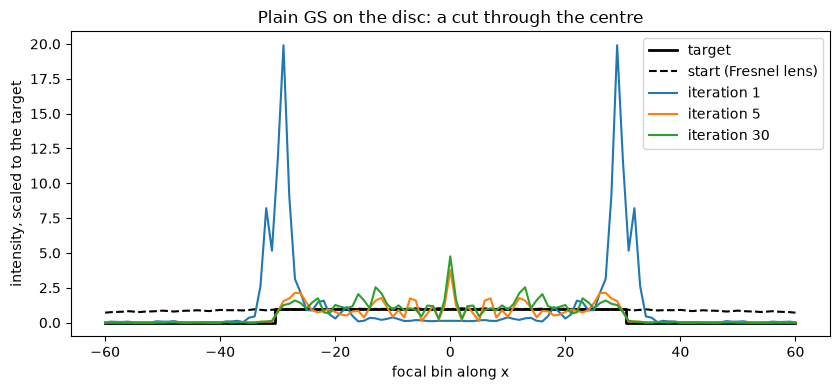

In [6]:
# the intensity along the x axis through the centre, scaled to the target, after 1, 5 and 30 iterations
c = setup.n_fft // 2
span = np.arange(c - 60, c + 61)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.step(span - c, (disc.amplitude[c, span] ** 2), where="mid", color="k", lw=2, label="target")
ax.plot(span - c, deviation_map(fresnel)[1][c, span], "k--", label="start (Fresnel lens)")
for k in (1, 5, 30):
    ax.plot(span - c, deviation_map(phis[k])[1][c, span], label=f"iteration {k}")
ax.set_xlabel("focal bin along x")
ax.set_ylabel("intensity, scaled to the target")
ax.set_title("Plain GS on the disc: a cut through the centre")
ax.legend()
fig.tight_layout()
plt.show()

The dashed start is nearly flat across the cut but extends well past the rim, which is where its power goes. After one iteration the light has gathered on the rim of the disc, with peaks about twenty times the target at the edge and almost nothing inside: the loop forces the amplitude inside the disc to the target, and the field that the SLM can actually make puts most of it at the edge. After five and thirty iterations the interior fills in, but with ripples from about a third of the target to two and a half times it and a peak of about 4.7 times at the centre, which is the speckle that a phase-only hologram leaves when every bin of the disc is forced. The figure shows a cut along one axis and says nothing about the two-dimensional pattern of the ripples, which the next figure maps.

The fourth step is the comparison the question asks for. The cell runs the same M04 on the nine traps with the same seed and budget and prints its efficiency, its uniformity and its relative spread, next to the same three numbers for the disc.

In [7]:
# the same algorithm on nine point traps, 30 iterations, for the comparison of the spread
points = m04_gs.run(setup, Target.from_traps(nine), budget=Budget(30), rng=Rng(seed))
last = points.history[-1]
print(f"nine traps: efficiency {last['efficiency']:.4f}, uniformity {last['uniformity']:.4f}, "
      f"relative spread {last['rel_std']:.2f} %")
print(f"disc: power in the signal region {history[-1]['efficiency']:.4f}, "
      f"relative spread {history[-1]['rel_std']:.2f} %")

nine traps: efficiency 0.8190, uniformity 0.8926, relative spread 6.81 %
disc: power in the signal region 0.9621, relative spread 44.11 %


On nine traps the loop reaches a relative spread of 6.81 percent and a uniformity of 0.8926, with 0.8190 of the power in the traps. On the disc it puts 0.9621 of the power in the signal region, more than for the traps, and gets a relative spread of 44.11 percent over the bins of the disc. The uniformity of the traps, built from the brightest and the dimmest trap, is not a number for a shape: over thousands of bins it is set by two extreme bins, and the product scores a shape by its error and the power in its signal region only. The same algorithm gives a good array and a poor disc. The power is not the issue, since the disc has more of it in its signal region; the issue is that the disc asks for a hologram whose light is flat over 2389 bins at once. The last figure maps where the disc is wrong and follows the spread of both targets through the iterations.

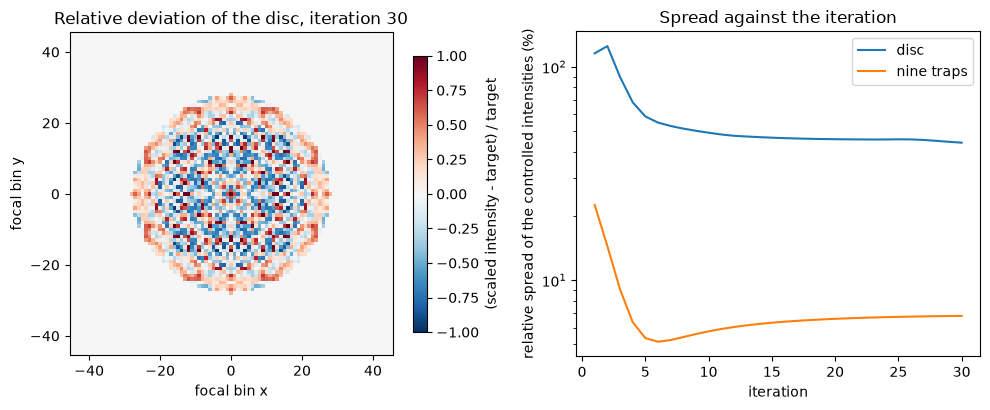

In [8]:
# the deviation map of the disc after 30 iterations, and the spread of both targets against the iteration
dev30 = deviation_map(phis[30])[0]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4.2))
window = np.s_[c - 45:c + 46, c - 45:c + 46]
clipped = np.clip(dev30[window], -1, 1)
shown = left.imshow(clipped, cmap="RdBu_r", vmin=-1, vmax=1, origin="lower", extent=(-45.5, 45.5, -45.5, 45.5))
left.set_xlabel("focal bin x")
left.set_ylabel("focal bin y")
left.set_title("Relative deviation of the disc, iteration 30")
fig.colorbar(shown, ax=left, label="(scaled intensity - target) / target", shrink=0.85)
right.semilogy(range(1, len(history) + 1), [h["rel_std"] for h in history], label="disc")
right.semilogy(range(1, len(points.history) + 1), [h["rel_std"] for h in points.history], label="nine traps")
right.set_xlabel("iteration")
right.set_ylabel("relative spread of the controlled intensities (%)")
right.set_title("Spread against the iteration")
right.legend()
fig.tight_layout()
plt.show()

On the left, the deviation map of the disc after thirty iterations is a symmetric lattice of red and blue cells that reaches the limits of the scale, plus and minus 100 percent, in the interior: there is no region that is right and a few that are wrong, the whole disc carries the speckle. On the right, the spread of the nine traps falls below 10 percent within five iterations and then drifts up slightly, while the spread of the disc starts above 100 percent, falls fast for ten iterations and then flattens near 44 percent. The disc has stopped improving, which points to the algorithm and not to the budget. The figure does not say whether any hologram can do better on this disc, only that this loop with this constraint stays where it is.

The last step looks at the edge. The measure region leaves out the bins within one resolution cell of the rim, because no hologram can place a sharp edge between two bins that the optics cannot tell apart. The cell scores the same hologram on the eroded region and on the whole shape, to see whether that choice hides a large part of the error.

In [9]:
# the edge: the same hologram scored on the whole shape and on the eroded measure region
whole = disc.amplitude > 0
wanted = disc.amplitude**2
intensity = np.abs(forward.fft_focal_field(phis[30], setup)) ** 2
for label, region in (("eroded measure region", core), ("whole shape", whole)):
    scale = wanted[region].sum() / intensity[region].sum()
    error = np.sqrt(np.mean(((scale * intensity[region] - wanted[region]) / wanted[region]) ** 2))
    print(f"{label}: {int(region.sum())} bins, error {error:.4f}")

eroded measure region: 2389 bins, error 0.4411
whole shape: 2861 bins, error 0.4306


## Results

**Answer:** A disc asks for a flat profile over 2389 bins, 265 times the nine numbers a 3 by 3 trap array asks for, out of the same 65536 phases, and plain Gerchberg-Saxton cannot give it: after 30 iterations the nine traps have a relative spread of 6.81 percent and the disc 44.11 percent, with an error of 0.4411 although 0.9621 of the power is in the signal region. The error is not an artefact of the edge: scored on the whole shape, 2861 bins, it is 0.4306, so the rim is not what the loop gets wrong. The error alone cannot be trusted either, because the engine's untouched start scores 0.0322 with only 0.0887 of the power in the signal region; a shaped potential is judged by its error and its power together. What the notebook does not show is a method that does better on the disc, which is the subject of the next notebooks.

## Summary

A point trap asks for one intensity and a disc asks for thousands, all equal. Plain Gerchberg-Saxton gives nine traps a 6.81 percent spread and the disc a 44.11 percent one, a speckle that fills the whole shape and that more iterations do not remove. The error must be read with the power fraction in the signal region, because a broad smooth start scores 0.0322 by leaving the light outside. The next notebook asks what happens when the method is allowed to put light outside the signal region on purpose.

## References

- Pasienski and DeMarco, "A high-accuracy algorithm for designing arbitrary holographic atom traps", Optics Express 16, 2176 (2008), https://doi.org/10.1364/OE.16.002176.
- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.